In [1]:
from __future__ import annotations
import operator 
from dotenv import load_dotenv
from typing import TypedDict, List, Annotated
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama
import os
from langchain_core.messages import SystemMessage, HumanMessage
from together import Together

In [7]:
import sys
!{sys.executable} -m pip install together



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
class Task(BaseModel):
    id : int
    title : str
    brief : str = Field(..., description="What to cover")
    goal : str = Field(
        ..., 
        description = "One sentence describing what the reader should be able to do / understand after this section.",
    )

    bullets : List[str] = Field(
        ...,
        min_length = 3, 
        max_length = 5,
        description = "3-5 concrete, non - overlapping subpoints to cover in this section.",
    )

    target_words : int = Field(
        ...,
        description="target word count for this section (120 - 450)."
    )

    section_type : Literal[
        "Engaging Headlines","intro", "core", "example", "checklist", "common_mistakes","Links", "conclusion"
    ] = Field(
        ...,
        description="use 'common_mistakes' exactly once in the plan.",
    )



TypeError: tuple indices must be integers or slices, not tuple

In [3]:
load_dotenv()

True

In [ ]:
from docutils.nodes import description
class Plan(BaseModel):
    blog_title: str
    tasks : List[Task]
    audience : str = Field(..., description="Who is the person this blog is for.")
    tone : str = Field(..., description="Writing tone (e.g., practical, crisp, updated).")

In [5]:
class State(TypedDict):
    topic : str
    plan : Plan
    # reducer : results from workers get concatenated automatically
    sections : Annotated[List[str], operator.add]
    final: str

In [6]:
llm = ChatOllama(
    model = "llama3.2:latest"
)

In [7]:
def orchestrator(state: State) -> dict:
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic"
                )
            ),
            HumanMessage(content=f'Topic : {state['topic']}'),
        ]
    )
    return {"plan": plan}

In [8]:
def fanout(state: State):
    return [Send("worker", {"task":task, "topic": state["topic"], "plan": state["plan"]})
    for task in state["plan"].tasks]


In [9]:
def worker(payload: dict) -> dict:
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog : {blog_title}\n",
                    f"Topic : {topic}\n",
                    f"Section : {task.title}\n",
                    f"Brief : {task.brief}\n\n",
                    "return only the section content in Markdown"

                )
            )
        ]
    ).content.strip()

    return {"sections":[section_md]}





In [10]:

from pathlib import Path
def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title} \n\n {body}"

    # saveingg to file
    filename = title.lower().replace(" ", "_")+".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}




In [11]:
g = StateGraph(State)
g.add_node('orchestrator', orchestrator)
g.add_node('worker', worker)
g.add_node('reducer', reducer)


In [12]:
g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ['worker'])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()


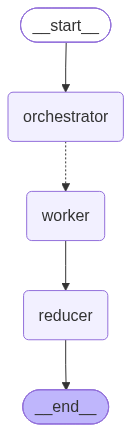

In [13]:
app

In [14]:
out = app.invoke({'topic':"write a blog on self attention in machine learning", "section":[]})

In [17]:
print(out["plan"])

blog_title='The Power of Self-Attention in Machine Learning: Unlocking the Secrets of Deep Learning Models' tasks=[Task(id=1, title='Introduction to Self-Attention', brief='Define self-attention and its importance in machine learning models'), Task(id=2, title='How Self-Attention Works', brief='Explain the mechanics of self-attention and its benefits in deep learning'), Task(id=3, title='Types of Self-Attention', brief='Discuss different types of self-attention and their applications in machine learning'), Task(id=4, title='Self-Attention in Transformer Models', brief='Explore the role of self-attention in transformer models and their applications'), Task(id=5, title='Advantages and Challenges of Self-Attention', brief='Discuss the advantages and challenges of using self-attention in machine learning models'), Task(id=6, title='Real-World Applications of Self-Attention', brief='Provide examples of real-world applications of self-attention in machine learning'), Task(id=7, title='Best P